In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import torch
from torchvision import models
from PIL import Image
import requests
import matplotlib.pyplot as plt
from io import BytesIO


In [2]:
device ='cpu'
weights = models.MobileNet_V3_Large_Weights.DEFAULT
model = models.mobilenet_v3_large(weights=weights)
model.classifier = torch.nn.Identity()
model = model.to(device).eval()
preprocessor = weights.transforms()

In [3]:
catalog = pd.read_csv('data/catalog.csv')
catalog.head()

,picture.id,outfit.id,file_name,image_path,group,embeddings_idx
0,picture.0000cdba64314d84a49ed1c266589cc0,outfit.794483397da8425a813301eecf9828c6,0000cdba64314d84a49ed1c266589cc0.jpg,/root/.cache/kagglehub/datasets/kaborg15/vibre...,group.0a045453ba8fda6cd089eb66930233fb,0
1,picture.00058abb53434872ae9bb4270ae21f8e,outfit.98f32aaf08bc4ff09c44e6e11e9199bc,00058abb53434872ae9bb4270ae21f8e.jpg,/root/.cache/kagglehub/datasets/kaborg15/vibre...,group.cd76a901746b1b6c34cb6ede1586461e,1
2,picture.00063f52c36d43ada95da45f819b30b4,outfit.9fd1c42c3db543c5b6e53b0db1ee8c0f,00063f52c36d43ada95da45f819b30b4.jpg,/root/.cache/kagglehub/datasets/kaborg15/vibre...,group.985203168fe1cc282e1da350315d9acc,2
3,picture.0008443461814f5c988f123718bbd20e,outfit.a7539783b6e94591bdf4e10339afc1d7,0008443461814f5c988f123718bbd20e.jpg,/root/.cache/kagglehub/datasets/kaborg15/vibre...,group.957dbc51df1f0cfa6f38cb99d7b1e52c,3
4,picture.000a5db3362049aebcc1eb2bf7bde95f,outfit.745fa2bc8156478bac6c0f7d46dadbda,000a5db3362049aebcc1eb2bf7bde95f.jpg,/root/.cache/kagglehub/datasets/kaborg15/vibre...,group.f34c702b93b819798d7827d8751c143e,4


In [4]:
embeddings = np.load('data/embeddings/embeddings.npy')
# Map embedding IDs to group in the catalog
id_to_group = catalog.set_index('embeddings_idx')['group'].to_dict()

In [5]:
def get_embedding(image):
    img = Image.open(image).convert('RGB')
    input = preprocessor(img).unsqueeze(0).to(device)
    with torch.no_grad():
        return model(input).squeeze().cpu().numpy()

In [ ]:
def get_similarity(image1, image2):
    return cosine_similarity(get_embedding(image1).reshape(1,-1), get_embedding(image2).reshape(1,-1))[0][0]

In [ ]:

def get_top_n_similar(embedding, all_embeddings, id_to_group, n):
    similarity = cosine_similarity(embedding.reshape(1,-1), all_embeddings)[0]
    top_id = np.argsort(similarity)[::-1]

    groups = set()
    id, score = [],[]

    for i in top_id:
        group = id_to_group[i]
        if group in groups:
            continue
        groups.add(group)
        id.append(i)
        score.append(similarity[i])
        if len(id) == n:
            break


    return id, score

In [ ]:
test_image = 'data/test_images/test_img_1.jpg'
test_image2 = 'data/test_images/test_img_2.jpg'
test_embedding = get_embedding(test_image)
top_ids, top_scores = get_top_n_similar(test_embedding, embeddings, id_to_group, 5)

test_embedding2 = get_embedding(test_image2)
top_ids2, top_scores2 = get_top_n_similar(test_embedding2, embeddings, id_to_group, 5)

In [9]:
base_url = 'https://huggingface.co/datasets/Keizano/images/resolve/main'

def get_image_url(file):
    subfolder = file['embeddings_idx'] // 5000+1
    return f'{base_url}/sub_{subfolder}/{file["file_name"]}'

def load_image(url):
    return Image.open(BytesIO(requests.get(url).content))


In [10]:
def show_results(test_image, top_ids, top_scores):
    fig, axes = plt.subplots(1, 6, figsize=(24, 5))

    axes[0].imshow(Image.open(test_image))
    axes[0].set_title('Input')

    for ax, idx, score in zip(axes[1:], top_ids, top_scores):
        row = catalog[catalog['embeddings_idx'] == idx].iloc[0]
        ax.imshow(load_image(get_image_url(row)))
        ax.set_title(f'{score:.3f}')

    for ax in axes:
        ax.axis('off')
    plt.show()

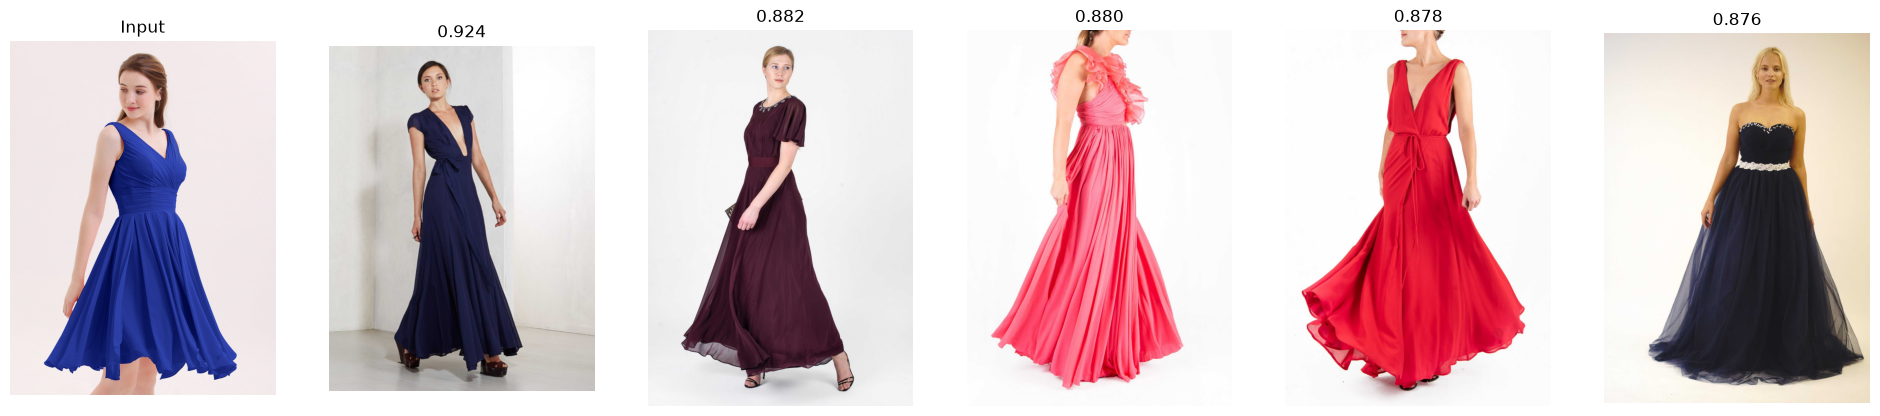

In [11]:
show_results(test_image, top_ids, top_scores)

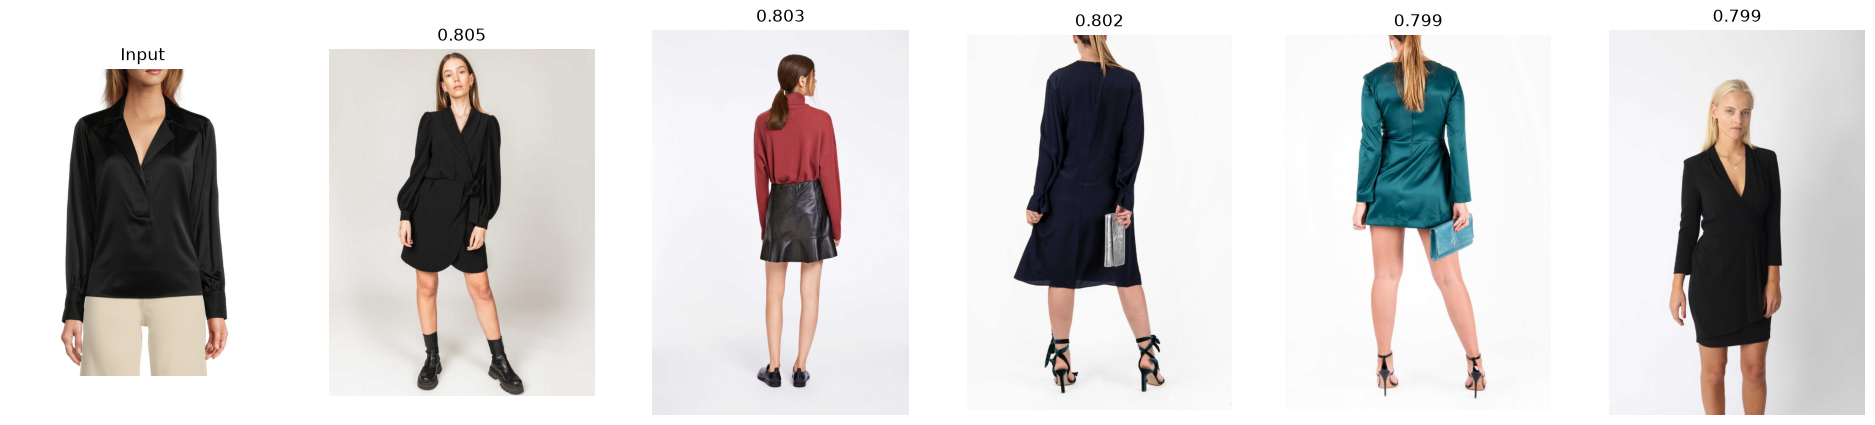

In [12]:
show_results(test_image2, top_ids2, top_scores2)

In [ ]:
# Compare the two test images
get_similarity(test_image, test_image2)

np.float32(0.36512738)